In [400]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.distributions import Categorical

In [401]:
def set_seed(seed):  #same seed for all libraries
    np.random.seed(seed)
    torch.manual_seed(seed)

In [402]:
SEED=42
set_seed(SEED)

In [403]:
def make_env(seed, render_mode=None):
    env = gym.make("LunarLander-v3", render_mode=render_mode)

    env.action_space.seed(seed) #fixe le seed pour action aleatoire
    env.observation_space.seed(seed) #fixe le seed pour observation aleatoire
    return env

In [404]:
env = make_env(seed=SEED, render_mode=None)
state, info = env.reset(seed=SEED) #reset environment 
print(state) #x, y vitesse_x, vitesse_y, angle, vitesse_angulaire, contact_gauche, contact_droit

[ 0.00229702  1.4181306   0.23264714  0.32046658 -0.00265488 -0.05269808
  0.          0.        ]


In [405]:
def get_end_reason(
        final_state,
        final_reward,
        terminated,
        truncated):
    if truncated:
        return "truncated" #max steps reached
    if not terminated:
        return "unknown" #unexpected termination
    if final_reward > 0:
        return "at rest" 
    if abs(final_state[0]) >= 1.0: #gauche ou droite
        return "out of bounds"
    return "crashed"

In [406]:
def run_random_agent(env, num_episodes, base_seed): #parameters 
    episode_rewards = [] #la recompense totale pour chaque épisode
    episode_lenghts = [] #le nombre de pas/etapes pour chaque épisode
    end_reasons = [] #la raison

    env.action_space.seed(base_seed)

    for episode in range(num_episodes):
        state, info = env.reset(seed=base_seed + episode) #on utilise un seed different pour chaque episode
        terminated = False
        truncated = False
        total_reward = 0
        episode_steps = 0

        while not (terminated or truncated):
            action = env.action_space.sample() #0 ne rien faire, 1 moteur gauche, 2 moteur principal, 3 moteur droit

            next_state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            episode_steps += 1
            state = next_state


        end_reason = get_end_reason(
            final_state = state,
            final_reward = reward, 
            terminated = terminated,
            truncated = truncated
        )
        #enregistre les res dans les listes
        episode_rewards.append(total_reward)
        episode_lenghts.append(episode_steps)
        end_reasons.append(end_reason)
        
    #retourne les res sous forme de dictionnaire
    return {
        "rewards": np.array(episode_rewards),
        "lengths": np.array(episode_lenghts),
        "end_reasons": end_reasons
    }


In [407]:
AGENT_EPISODES = 100

baseline_results = run_random_agent(env, num_episodes=AGENT_EPISODES, base_seed=SEED)

In [408]:
assert len(baseline_results["rewards"]) == AGENT_EPISODES
assert len(baseline_results["lengths"]) == AGENT_EPISODES
assert len(baseline_results["end_reasons"]) == AGENT_EPISODES

#verifie que toutes les recompenses sont valides (pas de NaN ou infini)
assert np.all(
    np.isfinite(baseline_results["rewards"])  
)

assert np.all(
    baseline_results["lengths"] > 0
)

print("Baseline data is valid")

Baseline data is valid


In [409]:
baseline_rewards = baseline_results["rewards"]
baseline_lengths = baseline_results["lengths"]

print(
    f"Episodes: {AGENT_EPISODES}"
)

print(
    f"Mean reward: "
    f"{baseline_rewards.mean():.2f}"
)

print(
    f"Reward standard deviation: "
    f"{baseline_rewards.std():.2f}"
)

print(
    f"Minimum reward: "
    f"{baseline_rewards.min():.2f}"
)

print(
    f"Maximum reward: "
    f"{baseline_rewards.max():.2f}"
)

print(
    f"Mean episode length: "
    f"{baseline_lengths.mean():.2f}"
)

Episodes: 100
Mean reward: -174.82
Reward standard deviation: 102.74
Minimum reward: -461.57
Maximum reward: 22.31
Mean episode length: 89.54


In [410]:
from collections import Counter

reason_counts = Counter(
    baseline_results["end_reasons"]
)

print("End reasons:")

for reason, count in reason_counts.items():
    print(f"{reason}: {count}")

End reasons:
crashed: 91
out of bounds: 9


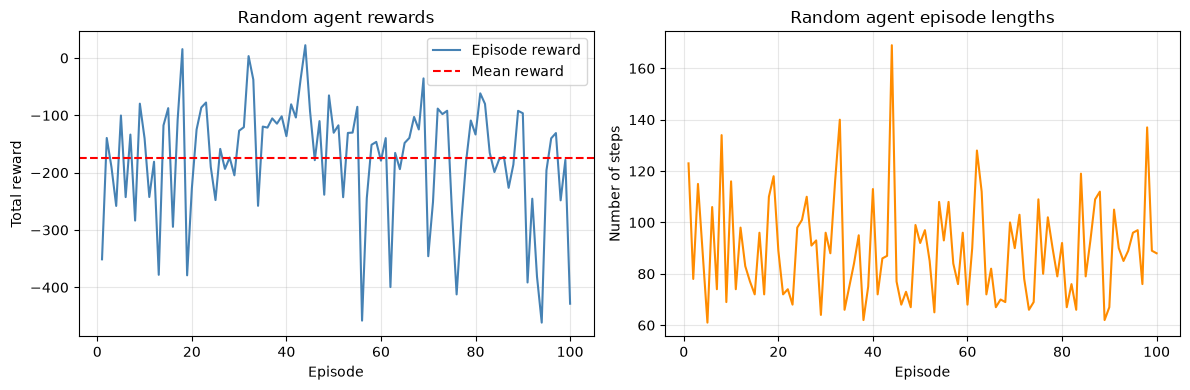

In [411]:
episodes = np.arange(1, AGENT_EPISODES + 1)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

axes[0].plot(
    episodes,
    baseline_rewards,
    color="steelblue",
    label="Episode reward",
)

axes[0].axhline(
    baseline_rewards.mean(),
    color="red",
    linestyle="--",
    label="Mean reward",
)

axes[0].set_title("Random agent rewards")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Total reward")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    episodes,
    baseline_lengths,
    color="darkorange",
)

axes[1].set_title("Random agent episode lengths")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Number of steps")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [412]:
state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size) 
print("Action size:", action_size)

State size: 8
Action size: 4


In [413]:
class ActorCritic(nn.Module):
    def __init__(self, state_size, action_size, hidden_size=64):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, action_size),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self,state):
        action_logits = self.actor(state)
        state_value = self.critic(state).squeeze(-1)  # Remove the last dimension
        return action_logits, state_value

    def get_action_and_value(
        self, state, action=None
    ):
        action_logits, state_value = self(state)

        distribution = Categorical(logits=action_logits)

        if action is None:
            action = distribution.sample()
        log_probability = distribution.log_prob(action)
        entropy = distribution.entropy()

        return (
            action, log_probability, entropy, state_value)
    

In [414]:
device = torch.device("cpu")

set_seed(SEED)

model = ActorCritic(
    state_size=state_size,
    action_size=action_size,
    hidden_size=64,
).to(device)

print(model)

ActorCritic(
  (actor): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [415]:
state, info = env.reset(seed=SEED)

state_tensor = torch.as_tensor(  #transforme le state en tensor pour le model
    state, 
    dtype = torch.float32,
    device=device
).unsqueeze(0)  # Add batch dimension


print("original state:", state.shape)
print("state tensor:", state_tensor.shape)



original state: (8,)
state tensor: torch.Size([1, 8])


In [416]:
with torch.no_grad():
    action, log_prob, entropy, state_value = (
        model.get_action_and_value(state_tensor)
    )

print("Action:", action.item())
print("Log probability:", log_prob.item())
print("Entropy:", entropy.item())
print("State value:", state_value.item())

Action: 0
Log probability: -1.4023222923278809
Entropy: 1.3858437538146973
State value: 0.14401423931121826


In [417]:
next_state, reward, terminated, truncated, info = env.step(action.item())

print("Next state:", next_state)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)

Next state: [ 0.00459394  1.424763    0.23233266  0.29476273 -0.00525882 -0.05208294
  0.          0.        ]
Reward: 1.1449811454510836
Terminated: False
Truncated: False


In [418]:
class RolloutStorage:
    def __init__(self):
        self.clear()

    def clear(self):
        self.states = []
        self.actions = []
        self.rewards = []
        self.next_states = []
        self.terminated = []
        self.truncated = []
        self.log_probs = []
        self.values = []

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        terminated,
        truncated,
        log_prob,
        value
    ):
        self.states.append(state.copy())
        self.actions.append(action)
        self.rewards.append(reward)
        self.next_states.append(next_state.copy())
        self.terminated.append(terminated)
        self.truncated.append(truncated)
        self.log_probs.append(log_prob)
        self.values.append(value)
    def __len__(self):
        return len(self.rewards)


In [419]:
storage = RolloutStorage()

storage.add(
    state=state,
    action=action.item(),
    reward=reward,
    next_state=next_state,
    terminated=terminated,
    truncated=truncated,
    log_prob=log_prob.item(),
    value=state_value.item(),
)

assert len(storage) == 1
assert storage.states[0].shape == (state_size,)
assert storage.next_states[0].shape == (state_size,)
assert 0 <= storage.actions[0] < action_size

print("Transition stored correctly")

Transition stored correctly


In [420]:
def state_to_tensor(state):
    return torch.tensor(
        state,
        dtype=torch.float32,
    ).unsqueeze(0)

def collect_rollout(
    env,
    model,
    storage,
    state,
    episode_reward,
    steps=256,
):
    storage.clear()
    finished_rewards = []

    for _ in range(steps):
        state_tensor = state_to_tensor(state)

        with torch.no_grad():
            action, log_prob, entropy, value = (
                model.get_action_and_value(state_tensor)
            )

        next_state, reward, terminated, truncated, info = (
            env.step(action.item())
        )

        storage.add(
            state,
            action.item(),
            reward,
            next_state,
            terminated,
            truncated,
            log_prob.item(),
            value.item(),
        )

        episode_reward += reward
        state = next_state

        if terminated or truncated:
            finished_rewards.append(episode_reward)
            episode_reward = 0
            state, info = env.reset()

    return state, episode_reward, finished_rewards


In [421]:
storage = RolloutStorage()

state, info = env.reset(seed=SEED)
episode_reward = 0

state, episode_reward, episode_rewards = collect_rollout(
    env,
    model,
    storage,
    state,
    episode_reward,
    steps=256,
)

print("Collected steps:", len(storage))
print("Finished episodes:", len(episode_rewards))
print("Episode rewards:", episode_rewards)

Collected steps: 256
Finished episodes: 2
Episode rewards: [np.float64(-115.83021066308171), np.float64(-150.10467886751974)]


In [422]:
states = torch.tensor(
    np.array(storage.states)
)

actions = torch.tensor(storage.actions)
rewards = torch.tensor(storage.rewards)

next_states = torch.tensor(
    np.array(storage.next_states)
)

terminated = torch.tensor(storage.terminated)
truncated = torch.tensor(storage.truncated)
old_log_probs = torch.tensor(storage.log_probs)
values = torch.tensor(storage.values)

print(states.dtype)
print(actions.dtype)
print(rewards.dtype)
print(terminated.dtype)

torch.float32
torch.int64
torch.float64
torch.bool


In [423]:
def compute_gae(
    model,
    rewards,
    values,
    next_states,
    terminated,
    truncated,
    gamma=0.99,
    gae_lambda=0.95,
):
    with torch.no_grad():
        _, next_values = model(next_states)

    advantages = torch.zeros_like(rewards)
    gae = 0.0

    for t in reversed(range(len(rewards))):
        bootstrap_mask = 1.0 - terminated[t].float()

        continue_mask = 1.0 - (
            terminated[t] | truncated[t]
        ).float()

        delta = (
            rewards[t]
            + gamma * bootstrap_mask * next_values[t]
            - values[t]
        )

        gae = (
            delta
            + gamma
            * gae_lambda
            * continue_mask
            * gae
        )

        advantages[t] = gae

    returns = advantages + values

    return advantages, returns

In [424]:
advantages, returns = compute_gae(
    model=model,
    rewards=rewards,
    values=values,
    next_states=next_states,
    terminated=terminated,
    truncated=truncated,
)

In [425]:
print("Advantages:", advantages.shape)
print("Returns:", returns.shape)

print("First advantages:", advantages[:5])
print("First returns:", returns[:5])

Advantages: torch.Size([256])
Returns: torch.Size([256])
First advantages: tensor([ -4.6192,  -7.1240,  -9.1390, -11.2604,  -6.6869], dtype=torch.float64)
First returns: tensor([ -4.4752,  -6.9781,  -8.9930, -11.1144,  -6.5414], dtype=torch.float64)


In [426]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0003,
)

_, new_log_probs, entropy, new_values = (
    model.get_action_and_value(
        states,
        actions,
    )
)

ratio = torch.exp(
    new_log_probs - old_log_probs
)

clipped_ratio = torch.clamp(
    ratio,
    0.8,
    1.2,
)

policy_loss = -torch.min(
    ratio * advantages,
    clipped_ratio * advantages,
).mean()

value_loss = (
    (new_values - returns) ** 2
).mean()

loss = (
    policy_loss
    + 0.5 * value_loss
    - 0.01 * entropy.mean()
)

optimizer.zero_grad()
loss.backward()

torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    0.5
)
optimizer.step()

print("Policy loss:", policy_loss.item())
print("Value loss:", value_loss.item())
print("Total loss:", loss.item())

Policy loss: 21.316152934040133
Value loss: 1024.2219255346106
Total loss: 533.4132623339274


In [438]:
TRAINING_UPDATES = 500
PPO_EPOCHS = 4

all_rewards = []
storage = RolloutStorage()

for update in range(TRAINING_UPDATES):
    # Собираем 256 новых шагов
    state, episode_reward, episode_rewards = collect_rollout(
        env,
        model,
        storage,
        state,
        episode_reward,
        steps=256,
    )

    all_rewards.extend(episode_rewards)

    # Превращаем сохранённые данные в tensors
    states = torch.tensor(
        np.array(storage.states)
    )

    actions = torch.tensor(storage.actions)
    rewards = torch.tensor(storage.rewards)

    next_states = torch.tensor(
        np.array(storage.next_states)
    )

    terminated = torch.tensor(storage.terminated)
    truncated = torch.tensor(storage.truncated)
    old_log_probs = torch.tensor(storage.log_probs)
    values = torch.tensor(storage.values)

    # Вычисляем advantages и returns
    advantages, returns = compute_gae(
        model=model,
        rewards=rewards,
        values=values,
        next_states=next_states,
        terminated=terminated,
        truncated=truncated,
    )

    advantages = (
        advantages - advantages.mean()
    ) / (
        advantages.std() + 1e-8
    )

    # Несколько раз обучаемся на собранных данных
    for epoch in range(PPO_EPOCHS):
        _, new_log_probs, entropy, new_values = (
            model.get_action_and_value(
                states,
                actions,
            )
        )

        ratio = torch.exp(
            new_log_probs - old_log_probs
        )

        clipped_ratio = torch.clamp(
            ratio,
            0.8,
            1.2,
        )

        policy_loss = -torch.min(
            ratio * advantages,
            clipped_ratio * advantages,
        ).mean()

        value_loss = (
            (new_values - returns) ** 2
        ).mean()

        loss = (
            policy_loss
            + 0.5 * value_loss
            - 0.01 * entropy.mean()
        )

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            0.5,
        )

        optimizer.step()

    if (update + 1) % 10 == 0:
        recent_rewards = all_rewards[-20:]

        if recent_rewards:
            mean_reward = np.mean(recent_rewards)
        else:
            mean_reward = 0

        print(
            f"Update {update + 1}, "
            f"mean reward: {mean_reward:.2f}, "
            f"loss: {loss.item():.2f}"
        )

Update 10, mean reward: -71.11, loss: 29.87
Update 20, mean reward: -71.93, loss: 15.78
Update 30, mean reward: -46.27, loss: 0.93
Update 40, mean reward: -7.85, loss: 11.70
Update 50, mean reward: 13.34, loss: 25.20
Update 60, mean reward: 29.92, loss: 154.79
Update 70, mean reward: 46.54, loss: 44.97
Update 80, mean reward: 43.65, loss: 15.78
Update 90, mean reward: 29.27, loss: 28.70
Update 100, mean reward: 28.61, loss: 8.88
Update 110, mean reward: 18.13, loss: 0.02
Update 120, mean reward: 31.29, loss: 47.30
Update 130, mean reward: 37.24, loss: 54.70
Update 140, mean reward: 48.30, loss: 21.77
Update 150, mean reward: 48.99, loss: 35.82
Update 160, mean reward: 62.70, loss: 27.97
Update 170, mean reward: 62.49, loss: 24.95
Update 180, mean reward: 55.52, loss: 206.19
Update 190, mean reward: 29.36, loss: 22.13
Update 200, mean reward: 50.77, loss: 42.07
Update 210, mean reward: 38.89, loss: 77.72
Update 220, mean reward: 52.29, loss: 159.07
Update 230, mean reward: 51.08, loss: 

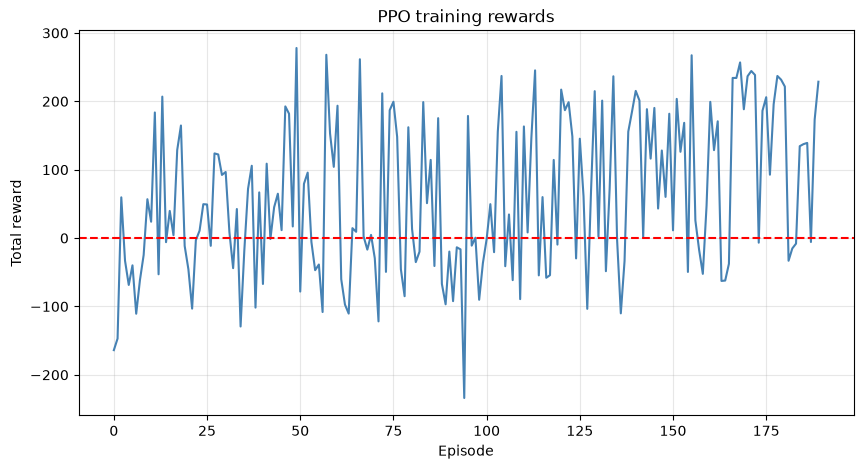

In [439]:
plt.figure(figsize=(10, 5))

plt.plot(
    all_rewards,
    color="steelblue",
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
)

plt.title("PPO training rewards")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.grid(alpha=0.3)

plt.show()

In [440]:
def evaluate_agent(env, model, episodes=20):
    rewards = []

    for episode in range(episodes):
        state, info = env.reset(seed=SEED + episode)
        total_reward = 0
        finished = False

        while not finished:
            state_tensor = state_to_tensor(state)

            with torch.no_grad():
                action, log_prob, entropy, state_value = model.get_action_and_value(state_tensor)

            action = action.item()

            state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward
            finished = terminated or truncated

        rewards.append(total_reward)

    return np.array(rewards)

In [441]:
evaluation_rewards = evaluate_agent(
    env,
    model,
    episodes=20,
)

print("Mean reward:", evaluation_rewards.mean())
print("Minimum reward:", evaluation_rewards.min())
print("Maximum reward:", evaluation_rewards.max())

Mean reward: 128.9446206573671
Minimum reward: -62.632201148672266
Maximum reward: 292.2191683663857


In [442]:
torch.save(
    model.state_dict(),
    "ppo_lunar_lander.pt",
)

print("Model saved")

Model saved


In [443]:
evaluation_rewards = evaluate_agent(
    env,
    model,
    episodes=100,
)

print("Mean reward:", evaluation_rewards.mean())
print("Standard deviation:", evaluation_rewards.std())
print("Minimum reward:", evaluation_rewards.min())
print("Maximum reward:", evaluation_rewards.max())
print(
    "Episodes above 200:",
    np.sum(evaluation_rewards >= 200),
)

Mean reward: 136.27745453036746
Standard deviation: 110.83941051657831
Minimum reward: -119.18349447999427
Maximum reward: 276.9039686477617
Episodes above 200: 37
